In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import joblib as jb 


# Description du dataset – Breast Cancer Wisconsin (Diagnostic)

## 1. Présentation générale

Le dataset *Breast Cancer Wisconsin (Diagnostic)* contient des données médicales permettant de caractériser des masses mammaires afin de déterminer si elles sont bénignes ou malignes.

Les caractéristiques présentes dans ce dataset sont extraites d'images numérisées obtenues par une technique appelée **Fine Needle Aspirate (FNA)**, qui consiste à prélever des cellules à l'aide d'une fine aiguille.

Les images sont ensuite analysées afin de mesurer différentes propriétés des noyaux cellulaires, notamment leur rayon, leur texture, leur périmètre, leur surface et leur forme.

## 2. Description des variables

Le dataset contient 10 caractéristiques principales extraites des noyaux cellulaires. Chacune est mesurée selon trois statistiques différentes :

- **Mean :** Moyenne des mesures.
- **SE (Standard Error) :** Erreur standard de la mesure.
- **Worst :** Valeur la plus élevée ou mesure la plus défavorable parmi les valeurs calculées.

Cela donne au total 30 variables explicatives.

| Caractéristique | Description |
|---|---|
| `radius` | Rayon moyen des noyaux cellulaires, calculé à partir du centre jusqu'au contour. |
| `texture` | Écart-type des niveaux de gris de l'image. |
| `perimeter` | Périmètre du noyau cellulaire. |
| `area` | Surface du noyau cellulaire. |
| `smoothness` | Variation locale des longueurs du rayon. |
| `compactness` | Mesure de la compacité du noyau, calculée à partir du périmètre et de la surface. |
| `concavity` | Degré de concavité du contour du noyau. |
| `concave_points` | Nombre ou mesure des portions concaves du contour. |
| `symmetry` | Niveau de symétrie du noyau cellulaire. |
| `fractal_dimension` | Mesure de la complexité du contour du noyau cellulaire. |



## 3. Objectif du clustering

Dans le cadre d'une étude non supervisée, ce dataset permet de regrouper les observations présentant des caractéristiques cellulaires similaires.

L'objectif est d'identifier des groupes de masses mammaires ayant des propriétés morphologiques proches, en se basant sur les 30 variables numériques disponibles.

## 4 - Source du dataset

[UCI Machine Learning Repository – Breast Cancer Wisconsin (Diagnostic)](https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic)


In [43]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
breast_cancer_wisconsin_diagnostic = fetch_ucirepo(id=17) 
  
# data (as pandas dataframes) 
df = breast_cancer_wisconsin_diagnostic.data.features 
y = breast_cancer_wisconsin_diagnostic.data.targets 

In [46]:
# affichage du dataset 
df.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [47]:
df.head(10).to_csv("sample_cancer.csv")

In [5]:
#info du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   radius1             569 non-null    float64
 1   texture1            569 non-null    float64
 2   perimeter1          569 non-null    float64
 3   area1               569 non-null    float64
 4   smoothness1         569 non-null    float64
 5   compactness1        569 non-null    float64
 6   concavity1          569 non-null    float64
 7   concave_points1     569 non-null    float64
 8   symmetry1           569 non-null    float64
 9   fractal_dimension1  569 non-null    float64
 10  radius2             569 non-null    float64
 11  texture2            569 non-null    float64
 12  perimeter2          569 non-null    float64
 13  area2               569 non-null    float64
 14  smoothness2         569 non-null    float64
 15  compactness2        569 non-null    float64
 16  concavit

In [6]:
#description du dataset
df.describe()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [7]:
#verification des valeurs manquante
df.isna().sum()

radius1               0
texture1              0
perimeter1            0
area1                 0
smoothness1           0
compactness1          0
concavity1            0
concave_points1       0
symmetry1             0
fractal_dimension1    0
radius2               0
texture2              0
perimeter2            0
area2                 0
smoothness2           0
compactness2          0
concavity2            0
concave_points2       0
symmetry2             0
fractal_dimension2    0
radius3               0
texture3              0
perimeter3            0
area3                 0
smoothness3           0
compactness3          0
concavity3            0
concave_points3       0
symmetry3             0
fractal_dimension3    0
dtype: int64

In [8]:
#verification doublons
df.duplicated().sum()

np.int64(0)

### <font color = 'yellow'>Exploration et preparation des données<font>

In [9]:
# renommer les index
df.index = ['patient' + str(i+1) for i in range(len(df))]
df.head()

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
patient1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
patient2,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
patient3,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
patient4,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
patient5,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [10]:
X = df.values

In [11]:
# Importer PCA
from sklearn.decomposition import PCA

#Instantier le modèle PCA avec n_components = 2
pca = PCA(n_components=2)
# Entrainer le modèle
features_pca = pca.fit_transform(X)

# Dataframe
df_pca = pd.DataFrame(features_pca,columns=['PCA1','PCA2'])


In [12]:
# Part de variance des 2 principaux composantes
round(sum(pca.explained_variance_ratio_*100),2)

np.float64(99.82)

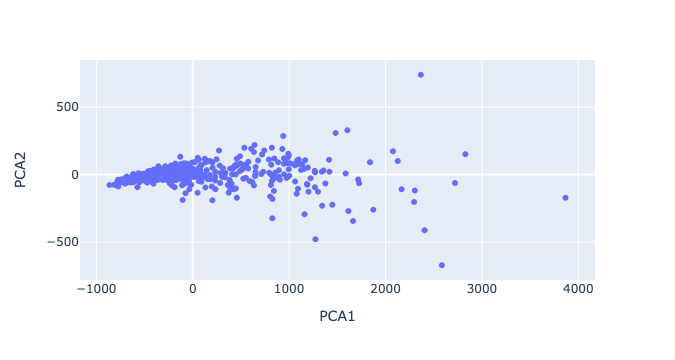

In [13]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2')
fig.show()

In [14]:
# Importer KMeans
from sklearn.cluster import KMeans

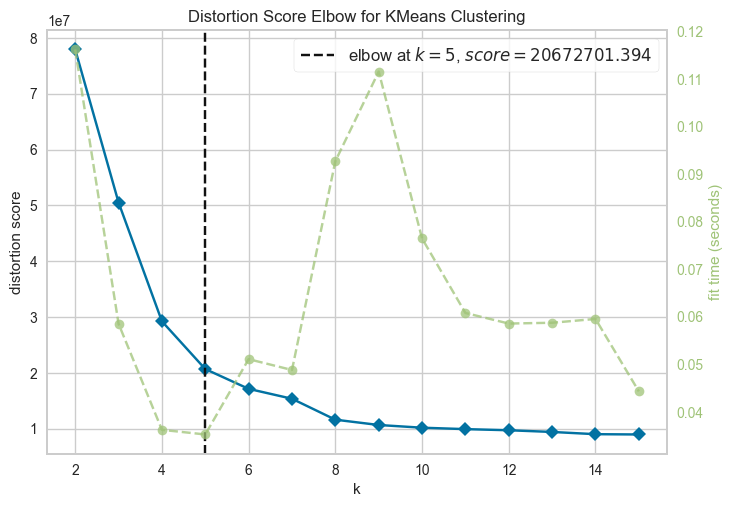

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [15]:
# importer KELbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500,random_state=42)
# Instantier KELbowVisualizer
Elbow_M = KElbowVisualizer(kmeans_model, k=15)
# Entrainement
Elbow_M.fit(X)
# Visualiser l'elbow
Elbow_M.show()

In [16]:
# instantier le modèle
kmeans_model = KMeans(n_clusters = 5, init = 'random', max_iter = 500,random_state=42)
# Entrainer le modèle
kmeans_model.fit(X)

,n_clusters,5
,init,'random'
,n_init,'auto'
,max_iter,500
,tol,0.0001
,verbose,0
,random_state,42
,copy_x,True
,algorithm,'lloyd'


In [17]:
# Prediction de la partition des données
kmeans_partition = kmeans_model.predict(X)
# Afficher la partition
kmeans_partition[: 100]

array([3, 3, 3, 2, 3, 1, 3, 1, 1, 1, 4, 4, 4, 1, 1, 1, 4, 4, 3, 1, 1, 2,
       1, 0, 3, 4, 1, 4, 4, 4, 3, 1, 4, 3, 4, 4, 1, 2, 1, 1, 1, 2, 3, 1,
       1, 3, 2, 1, 2, 1, 2, 1, 2, 4, 4, 2, 3, 1, 1, 2, 2, 2, 1, 2, 1, 1,
       2, 2, 2, 2, 3, 2, 3, 1, 1, 4, 1, 3, 3, 1, 2, 1, 0, 4, 2, 3, 1, 3,
       2, 1, 1, 1, 1, 1, 4, 3, 2, 2, 2, 1], dtype=int32)

In [18]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_kmeans = silhouette_score(X,kmeans_partition)
print(f"La silhouette score : {sil_kmeans} ")

La silhouette score : 0.507139518100327 


In [19]:
# Function de visualisation du diagramme en barre des nombres d'observations.
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

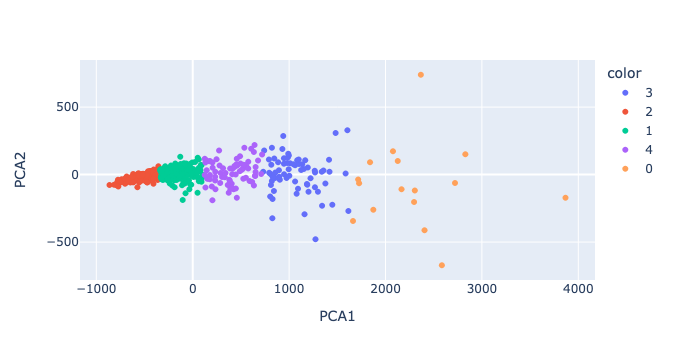

In [20]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2',color=kmeans_partition.astype(str))
fig.show()

### <font color='gold'> CAH

In [21]:
# importer linkage et le dendrogram
from scipy.cluster.hierarchy import linkage , dendrogram

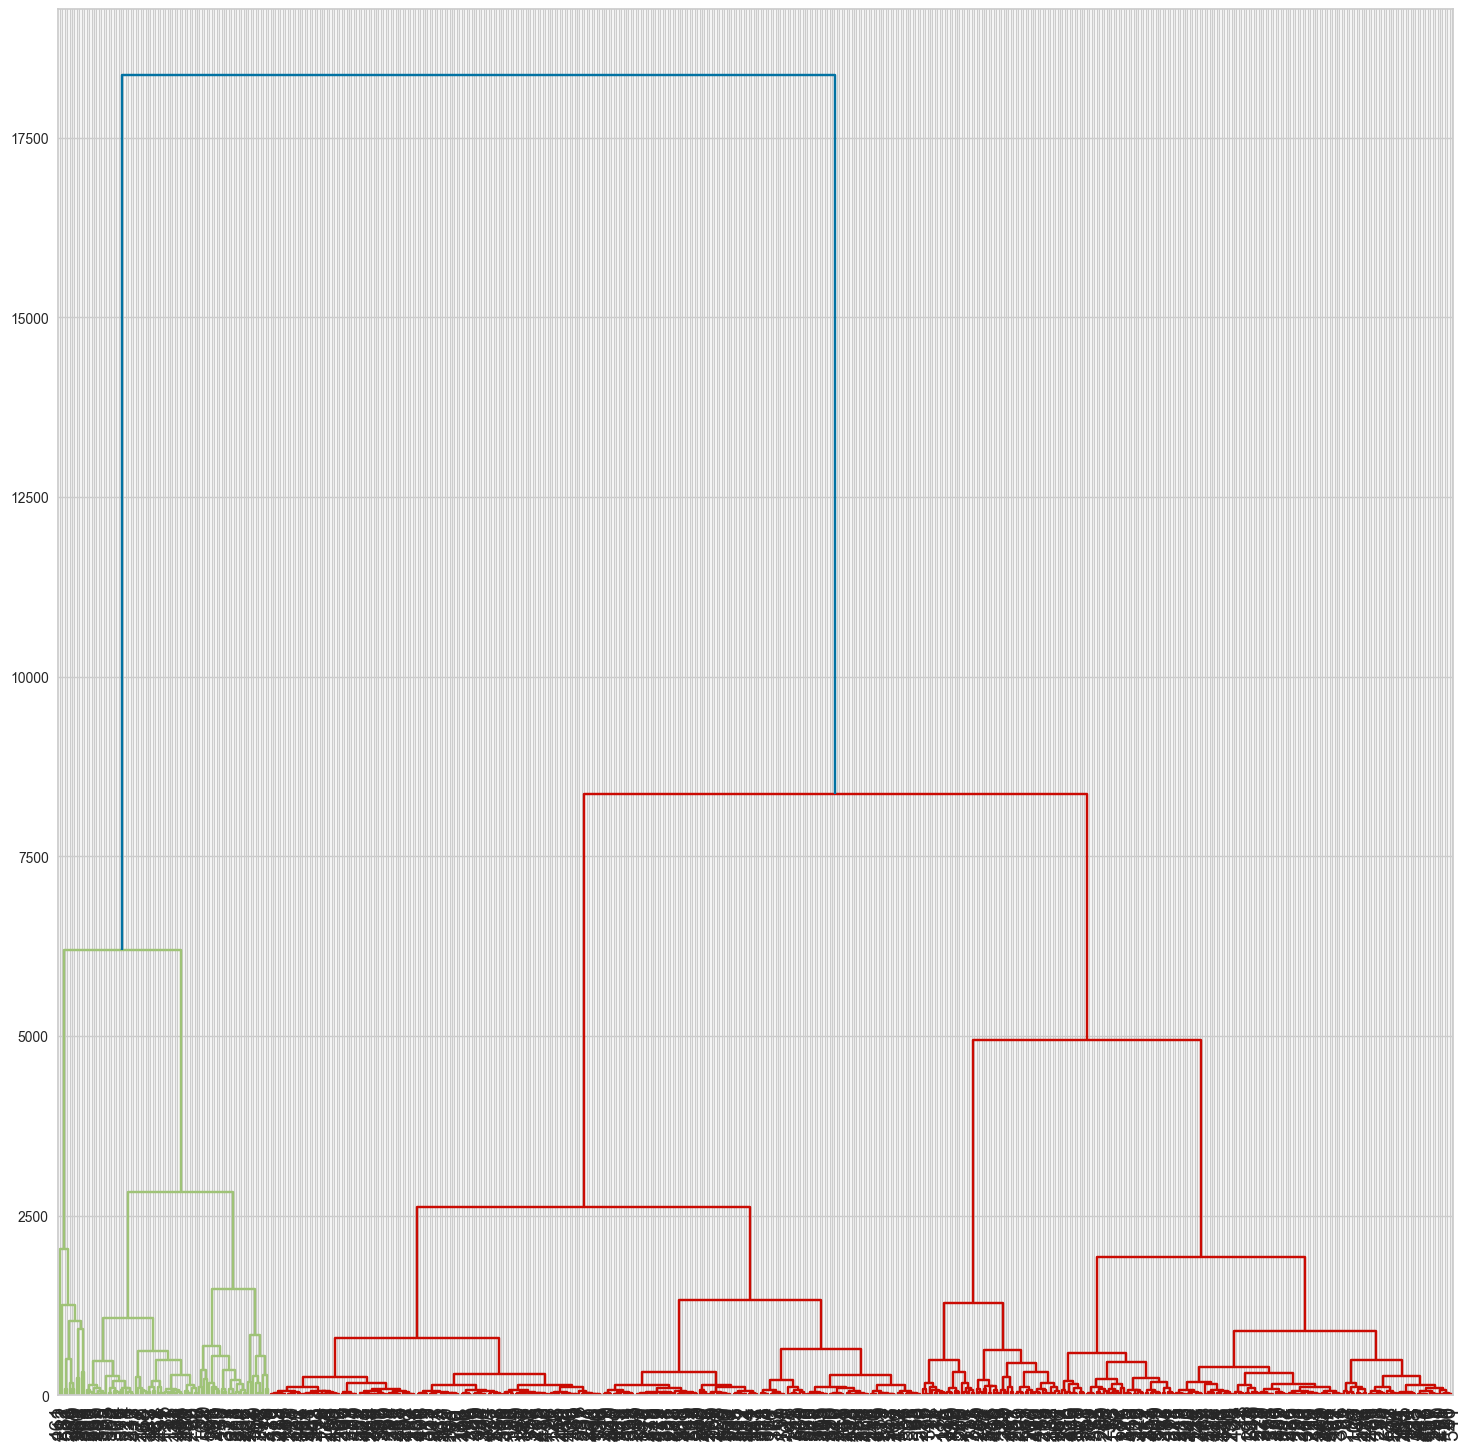

In [22]:
# visualisation du dendrogram
z = linkage(X,'ward')
plt.figure(figsize=(18,18))
dendro = dendrogram(z,leaf_font_size=15,orientation='top')

In [23]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters =2, linkage = 'ward')
# Entrainer le modèle
cah_model.fit(X)

,n_clusters,2
,metric,'euclidean'
,memory,None
,connectivity,None
,compute_full_tree,'auto'
,linkage,'ward'
,distance_threshold,None
,compute_distances,False


In [24]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(X)
# Afficher la partition
cah_partition[:100]

array([1, 1, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0,
       0, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0,
       0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 0, 1, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0])

In [25]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts()
val1

0    483
1     86
Name: count, dtype: int64

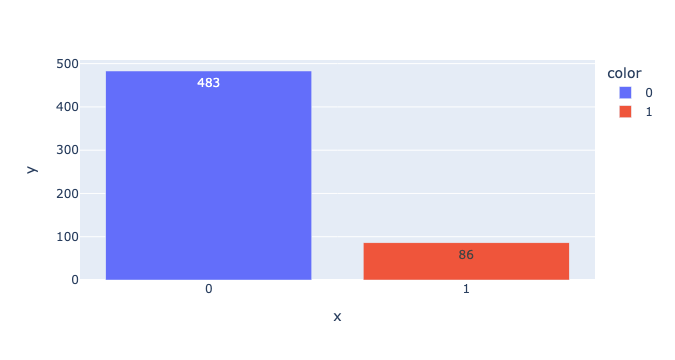

In [26]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

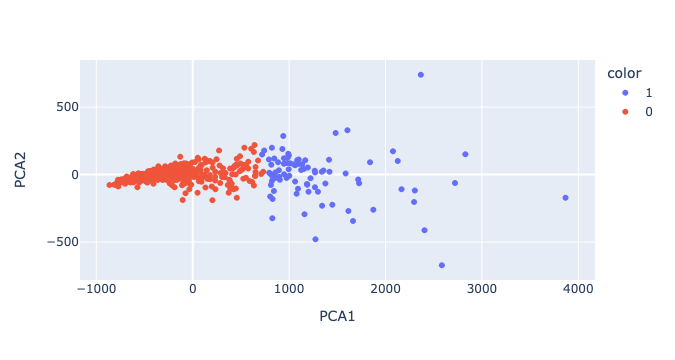

In [27]:
# Visualiser les classes suivant les deux composantes en utilisant plotly.express
fig = px.scatter(df_pca, x = 'PCA1', y = 'PCA2',color=cah_partition.astype(str))
fig.show()

In [28]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_cah = silhouette_score(X,cah_partition)
print(f"La silhouette score : {sil_cah} ")

La silhouette score : 0.6899796318793474 


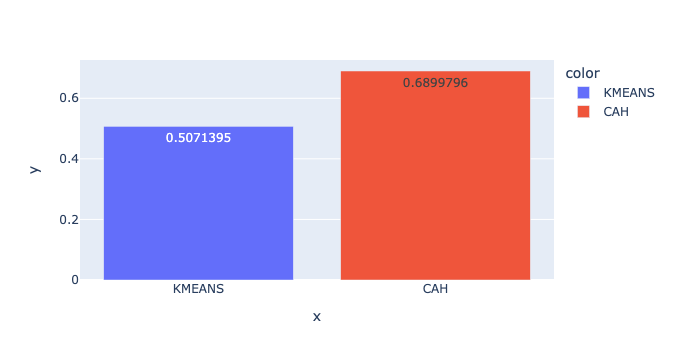

In [29]:
# Diagrammes en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_kmeans, sil_cah]
fig = px.bar(x= Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

In [30]:
# les indidivus
cluster_names = []
for i in range(2):
  cluster_names.append(list(df.index[cah_partition == i]))

In [31]:
# Les individus de la classe 0
print(cluster_names[0][:10])

['patient4', 'patient6', 'patient8', 'patient9', 'patient10', 'patient11', 'patient12', 'patient13', 'patient14', 'patient15']


#### <font color='gold'> Interpréter les classes

In [32]:
# Profil moyen de chaque classe (sans les anomalies)
profil = df.groupby(cah_partition).mean().round(2)
profil

,radius1,texture1,perimeter1,area1,smoothness1,compactness1,concavity1,concave_points1,symmetry1,fractal_dimension1,...,radius3,texture3,perimeter3,area3,smoothness3,compactness3,concavity3,concave_points3,symmetry3,fractal_dimension3
0,13.00,18.81,84.22,537.38,0.1,0.10,0.07,0.04,0.18,0.06,...,14.66,25.04,96.15,684.00,0.13,0.23,0.23,0.1,0.29,0.08
1,20.44,21.97,135.52,1314.84,0.1,0.16,0.20,0.11,0.19,0.06,...,25.31,29.23,169.66,1984.64,0.14,0.38,0.48,0.2,0.31,0.09


In [33]:
import numpy as np
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([X[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouveau_client):
    client = np.array(nouveau_client, dtype=float).reshape(1, -1)
    distances = cdist(client, centroides)
    return classes[distances.argmin()]

In [38]:
# telechargemebt du centroide
import joblib as jb
jb.dump(centroides, "centroides_cah_cancer.joblib")

['centroides_cah_cancer.joblib']

In [39]:
# Test rapide
print("Classe prédite  :", predire_classe(df.iloc[2].values))
print("Classe réelle de la CAH:", cah_partition[2])

Classe prédite  : 1
Classe réelle de la CAH: 1


In [40]:
# Noms des classes
noms_classes = {
    0: "Bénigne",
    1: "Maligne"
}

In [41]:
# telechargement du meilleur model 
jb.dump(cah_model,'model_cancer.joblib')

['model_cancer.joblib']